# Load UKMO data

Support provided for the [UK Met Office](https://www.metoffice.gov.uk/) Unified Model (UM) global deterministic 10 km forecasts. Forecasts are read from the public `met-office-atmospheric-model-data` S3 bucket.

No credentials are required, but the optional dependencies must be installed with `pip install pycontrails[ukmo]`.

This datalib currently supports air temperature, relative humidity, and specific humidity (derived from the other two) only. It does not provide winds, so the UKMO data cannot be used on its own to run CoCiP. It does provide the fields required by the ISSR, SAC, and PCR models. Fields are available on standard pressure levels only, spaced 25 hPa apart (roughly 1,900 to 3,200 ft) near cruise altitudes. This is coarse compared with model-level data, so thin ice-supersaturated layers are not resolved.

The examples below use forecasts from July 2026. The bucket holds roughly two years of forecasts, so the dates in this notebook will eventually need to be updated.

## Forecast availability

The UM global model is initialized at 0Z, 6Z, 12Z, and 18Z. The forecast horizon and timestep depend on the initialization time:

| Initialization | Hourly data | 3-hourly data | 6-hourly data |
|---|---|---|---|
| 0Z, 12Z | to +54h | to +144h | to +168h |
| 6Z, 18Z | to +54h | to +69h | none |

(Forecasts initialized at 6Z and 18Z before 2026-01-21 18z end at +66h instead of +69h.)

Fields are provided on a regular latitude-longitude grid with 2560 x 1920 points (0.140625 degrees in longitude and 0.09375 degrees in latitude, approximately 10 km at midlatitudes). This datalib does not support regridding.

In [1]:
import warnings

from pycontrails.datalib.ukmo import UM10

# ignore an upstream xarray warning about the default for combining files
warnings.filterwarnings(message=r"[\s\S]* default value for coords [\s\S]*", action="ignore")

## Selecting a forecast

By default, all data comes from the single forecast cycle with the shortest lead times that covers the requested time range:

In [2]:
um = UM10(
    time=("2026-07-15 12:00", "2026-07-15 13:00"),
    variables=("t", "q"),
    pressure_levels=[300, 250, 200],
)
um

UM10
	Timesteps: ['2026-07-15 12', '2026-07-15 13']
	Variables: ['t', 'q']
	Pressure levels: [200, 250, 300]
	Grid: None

In [3]:
um.forecast_time

datetime.datetime(2026, 7, 15, 12, 0)

A specific forecast cycle can be selected using the `forecast_time` parameter:

In [4]:
um = UM10(
    time=("2026-07-15 12:00", "2026-07-15 13:00"),
    forecast_time="2026-07-15 00:00",
    variables=("t", "q"),
    pressure_levels=[300, 250, 200],
)
um.forecast_time

datetime.datetime(2026, 7, 15, 0, 0)

Timesteps are hourly, three-hourly, or six-hourly depending on how far into the forecast the requested time range extends. This week-long time range extends to the end of the 12Z forecast, where only six-hourly data is available:

In [5]:
um = UM10(
    time=("2026-07-08 12:00", "2026-07-15 12:00"),
    variables=("t", "q"),
    pressure_levels=[300, 250, 200],
)
print("Forecast time:", um.forecast_time)
print("Timestep:", um.timesteps[1] - um.timesteps[0])
print("Number of timesteps:", len(um.timesteps))

Forecast time: 2026-07-08 12:00:00
Timestep: 6:00:00
Number of timesteps: 29


The time range must be short enough for a single forecast to cover it, otherwise a `ValueError` is raised. Longer time ranges can be retrieved using the `lead_hours` parameter, which uses data at a fixed lead time instead of from a single forecast. Each timestep then comes from a different forecast, initialized `lead_hours` earlier. Because forecasts are initialized every 6 hours, timesteps are six-hourly (or twelve-hourly for leads of more than 69 hours, which only the 0Z and 12Z forecasts reach). `lead_hours` cannot be combined with `forecast_time`.

In [6]:
um = UM10(
    time=("2026-07-01 00:00", "2026-07-15 00:00"),
    lead_hours=24,
    variables=("t", "q"),
    pressure_levels=[300, 250, 200],
)
print("Timestep:", um.timesteps[1] - um.timesteps[0])
print("Number of timesteps:", len(um.timesteps))

Timestep: 6:00:00
Number of timesteps: 57


## Retrieving data

By default, fields are provided at 300, 275, 250, 225, 200, 175, and 150 hPa (approximately 30,000 to 44,600 ft). Other pressure levels between 1000 hPa and 10 hPa can be requested using the `pressure_levels` parameter. Only the variables requested are cached, and specific humidity is derived from temperature and relative humidity, so requesting it downloads both fields.

The archive stores each field for the entire globe, so each forecast hour downloads roughly 370 MB for temperature and relative humidity. Processed data is cached locally so repeated requests are much faster.

In [7]:
um = UM10(
    time=("2026-07-15 12:00", "2026-07-15 13:00"),
    variables=("t", "q"),
    pressure_levels=[300, 250, 200],
)
mds = um.open_metdataset()
mds

MetDataset with data:

<xarray.Dataset> Size: 236MB
Dimensions:                  (longitude: 2560, latitude: 1920, level: 3, time: 2)
Coordinates:
  * longitude                (longitude) float64 20kB -179.9 -179.8 ... 179.9
  * latitude                 (latitude) float64 15kB -89.95 -89.86 ... 89.95
  * level                    (level) float64 24B 200.0 250.0 300.0
    air_pressure             (level) float32 12B 2e+04 2.5e+04 3e+04
    altitude                 (level) float32 12B 1.178e+04 1.036e+04 9.164e+03
  * time                     (time) datetime64[ns] 16B 2026-07-15T12:00:00 20...
    forecast_period          (time) timedelta64[ns] 16B 00:00:00 01:00:00
    forecast_reference_time  datetime64[ns] 8B 2026-07-15T12:00:00
Data variables:
    air_temperature          (longitude, latitude, level, time) float32 118MB dask.array<chunksize=(1280, 960, 1, 1), meta=np.ndarray>
    specific_humidity        (longitude, latitude, level, time) float32 118MB dask.array<chunksize=(2560, 1920, 3, 1), meta=np.ndarray>
Attributes:
    pycontrails_version:  0.64.1.dev28
    provider:             UKMO
    dataset:              UM-10
    product:              forecast

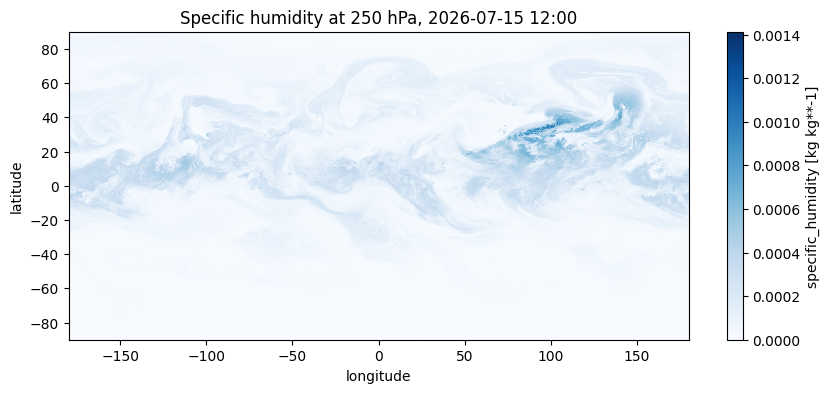

In [8]:
q = mds["specific_humidity"].data.sel(level=250).isel(time=0)
q.plot(
    x="longitude",
    y="latitude",
    figsize=(10, 4),
    cmap="Blues",
).axes.set_title("Specific humidity at 250 hPa, 2026-07-15 12:00");

## Persistent contrail regions

Air temperature and specific humidity are sufficient to evaluate the Schmidt-Appleman criterion (SAC), ice supersaturated regions (ISSR), and persistent contrail regions (PCR = SAC & ISSR). See the [SAC](SAC.ipynb) and [ISSR](ISSR.ipynb) notebooks for more on these models.

In [9]:
from pycontrails.models.pcr import PCR
from pycontrails.models.sac import SAC

sac = SAC(met=mds).eval()
pcr = PCR(met=mds).eval()

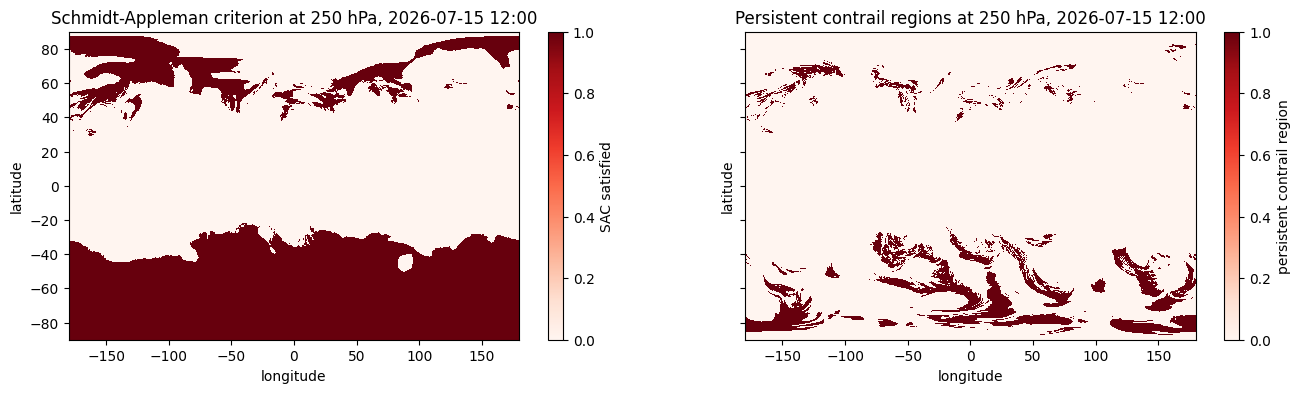

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)

sac["sac"].data.sel(level=250).isel(time=0).plot(
    ax=axes[0],
    x="longitude",
    y="latitude",
    cmap="Reds",
    cbar_kwargs={"label": "SAC satisfied"},
)
axes[0].set_title("Schmidt-Appleman criterion at 250 hPa, 2026-07-15 12:00")

pcr["pcr"].data.sel(level=250).isel(time=0).plot(
    ax=axes[1],
    x="longitude",
    y="latitude",
    cmap="Reds",
    cbar_kwargs={"label": "persistent contrail region"},
)
axes[1].set_title("Persistent contrail regions at 250 hPa, 2026-07-15 12:00");

## Using UKMO data with CoCiP

This datalib does not provide the winds, vertical velocity, ice water content, or radiative fluxes that CoCiP requires, so it cannot run CoCiP on its own. 

It is possible to take the missing fields from another source and combine them with UKMO temperature and humidity. This example uses the credential-free [ARCO ERA5](ARCO-ERA5.ipynb) interface (which needs `pip install pycontrails[zarr]`) for the missing fields.

This combines fields from two different models, so the result is a demonstration and not a validated configuration. Temperature and humidity come from the UM, but the winds that advect and spread contrails come from ERA5 and are not necessarily consistent with the UM's thermodynamic fields. Fields from ERA5 are interpolated linearly to the UKMO grid.

ARCO ERA5 model level data is updated with a delay of a few months, which is why this notebook uses a forecast from July 2026. Reading the ERA5 model level data is slow (several minutes). The region is limited to the North Atlantic to reduce the memory and time needed.

In [11]:
import warnings

import dask.config
import numpy as np
import xarray as xr

from pycontrails import MetDataset
from pycontrails.datalib.ecmwf import ERA5ARCO
from pycontrails.models.cocipgrid import CocipGrid
from pycontrails.models.humidity_scaling import ConstantHumidityScaling
from pycontrails.models.ps_model import PSGrid
from pycontrails.physics import units

time = ("2026-07-15 12:00", "2026-07-15 16:00")
pressure_levels = [300, 250, 200]
bbox = (-60, 40, -10, 60)  # (west, south, east, north)

# ignore a harmless pycontrails warning from the aircraft performance model
warnings.filterwarnings(message="some failed to converge", action="ignore")

Retrieve UKMO temperature and humidity, and the ERA5 fields that CoCiP requires:

In [12]:
um = UM10(time=time, variables=("t", "q"), pressure_levels=pressure_levels)
ukmo = um.open_metdataset().downselect(bbox)

era5 = ERA5ARCO(
    time=time,
    variables=("u", "v", "w", "ciwc"),
    pressure_levels=pressure_levels,
    cachestore=None,
)
era5 = era5.open_metdataset().downselect(bbox)

era5_rad = ERA5ARCO(
    time=time,
    variables=CocipGrid.rad_variables,
    pressure_levels=-1,
    cachestore=None,
)
rad = era5_rad.open_metdataset().downselect(bbox)

Load the data into memory. This computation is run in single-threaded mode, which reduces the memory used when converting ERA5 model level data to pressure levels.

In [13]:
with dask.config.set(scheduler="single-threaded"):
    ukmo.data.load()
    era5.data.load()
    rad.data.load()

Interpolate the ERA5 fields to the UKMO grid, and combine them with UKMO temperature and humidity into a single `MetDataset`. (The radiative fluxes in `rad` are passed to CoCiP separately, so they do not need to be on the same grid.)

In [14]:
era5_on_ukmo_grid = era5.data.interp(
    longitude=ukmo.data["longitude"], latitude=ukmo.data["latitude"]
)
met = MetDataset(xr.Dataset({**ukmo.data.data_vars, **era5_on_ukmo_grid.data_vars}))
met

MetDataset with data:

<xarray.Dataset> Size: 46MB
Dimensions:                              (time: 5, latitude: 213,
                                          longitude: 356, level: 3)
Coordinates:
  * time                                 (time) datetime64[ns] 40B 2026-07-15...
    forecast_period                      (time) timedelta64[ns] 40B 00:00:00 ...
  * latitude                             (latitude) float64 2kB 40.08 ... 59.95
  * longitude                            (longitude) float64 3kB -59.98 ... -...
  * level                                (level) float64 24B 200.0 250.0 300.0
    air_pressure                         (level) float64 24B 2e+04 2.5e+04 3e+04
    altitude                             (level) float64 24B 1.178e+04 ... 9....
    forecast_reference_time              datetime64[ns] 8B 2026-07-15T12:00:00
Data variables:
    air_temperature                      (longitude, latitude, level, time) float32 5MB ...
    specific_humidity                    (longitude, latitude, level, time) float32 5MB ...
    eastward_wind                        (longitude, latitude, level, time) float64 9MB ...
    northward_wind                       (longitude, latitude, level, time) float64 9MB ...
    lagrangian_tendency_of_air_pressure  (longitude, latitude, level, time) float64 9MB ...
    specific_cloud_ice_water_content     (longitude, latitude, level, time) float64 9MB ...

Run gridded CoCiP at 38,000 ft:

In [15]:
params = {
    "dt_integration": np.timedelta64(5, "m"),
    "max_age": np.timedelta64(2, "h"),
    "humidity_scaling": ConstantHumidityScaling(rhi_adj=1.0),
    "aircraft_performance": PSGrid(),
    "show_progress": False,
}

source = MetDataset.from_coords(
    level=units.ft_to_pl(38_000),
    time="2026-07-15 13:00",
    longitude=met["longitude"].values,
    latitude=met["latitude"].values,
)

cocip_grid = CocipGrid(met=met, rad=rad, params=params)
result = cocip_grid.eval(source)

Plot results:

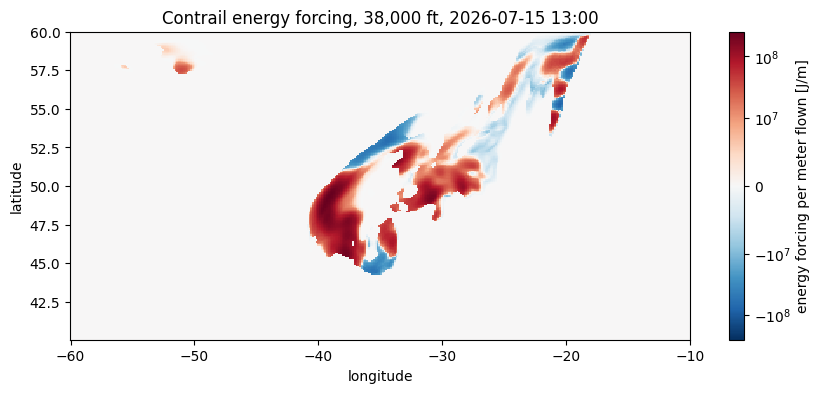

In [16]:
import matplotlib.colors

result["ef_per_m"].data.isel(level=0, time=0).plot(
    x="longitude",
    y="latitude",
    figsize=(10, 4),
    cmap="RdBu_r",
    norm=matplotlib.colors.SymLogNorm(linthresh=1e7),
    cbar_kwargs={"label": "energy forcing per meter flown [J/m]"},
).axes.set_title("Contrail energy forcing, 38,000 ft, 2026-07-15 13:00");